# Project01 · Evaluation

Code thực nằm trực tiếp trong cell. Các module backend là export của những cell này; chỉnh thuật toán ở notebook rồi chạy `notebook_source.py export`. Notebook 01 chứa model/retrieval, 02 chứa agent/API, 03 chứa evaluator/plot. Không cần mở `.py` để xem implementation. `%%project_module` thực thi source trong cell ở namespace riêng; không đọc implementation từ file khác.

Mặc định không train, không TEST cũ, không tự chạy evaluation. Kết quả bên dưới là demo development hoặc đọc output đã lưu.

In [1]:
from pathlib import Path
import sys, os, types, __future__
from IPython.core.magic import register_cell_magic
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'datasets/assets.json').exists() and (p/'notebooks').exists())
sys.path.insert(0,str(PROJECT/'web/backend'))
os.environ['OPENBLAS_NUM_THREADS']='1'
RUN_TRAINING=False
RUN_TEST=False
RUN_EVALUATION=False
@register_cell_magic
def project_module(line,cell):
    name=line.strip()
    parent,_,child=name.rpartition('.')
    if parent not in sys.modules:
        package=types.ModuleType(parent);package.__path__=[str(PROJECT/'web/backend/project01_core')];sys.modules[parent]=package
    module=sys.modules.get(name)
    if module is None:
        module=types.ModuleType(name);module.__package__=parent;module.__file__=str(PROJECT/'web/backend'/Path(*name.split('.')).with_suffix('.py'));sys.modules[name]=module;setattr(sys.modules[parent],child,module)
    exec(compile(cell,'<project01-notebook>/'+name,'exec',flags=__future__.annotations.compiler_flag,dont_inherit=True),module.__dict__)


## evaluation

Evaluator, ghi output một lần, so sánh số, retrieval và plot; gold chỉ vào evaluator, không vào agent.

In [2]:
%%project_module project01_core.evaluation
"""New task-set evaluation only; no historical model/QA TEST reader or tuning loop."""



In [3]:
%%project_module project01_core.evaluation
from pathlib import Path



In [4]:
%%project_module project01_core.evaluation
import json



In [5]:
%%project_module project01_core.evaluation
import math



In [6]:
%%project_module project01_core.evaluation
import os



In [7]:
%%project_module project01_core.evaluation
import platform



In [8]:
%%project_module project01_core.evaluation
import time



In [9]:
%%project_module project01_core.evaluation
import numpy as np



In [10]:
%%project_module project01_core.evaluation
from project01_core.agents import assist



In [11]:
%%project_module project01_core.evaluation
from project01_core.foundation import Runtime, digest, file_sha, read_json



### case_request

In [12]:
%%project_module project01_core.evaluation
def case_request(case):
    mode='combined' if case['category'] in {'combined','fault'} else 'numeric' if case['category'] in {'numeric','missing'} else 'knowledge'
    return {'mode':mode,'question':case['question'],'profile':case['profile'],'language':case['language']}



### judge_automatic

In [13]:
%%project_module project01_core.evaluation
def judge_automatic(case,result,reference_score):
    category=case['category'];risk=result['risk'];knowledge=result['knowledge'];status=result['status']
    numeric_ok=risk is not None and reference_score is not None and math.isclose(risk['score'],reference_score,rel_tol=1e-6,abs_tol=1e-6)
    integrity=bool(knowledge and knowledge['citations'] and all(key in {row['chunk_id'] for row in knowledge['evidence']} for key in knowledge['citations']))
    if category=='knowledge':success=status=='answered' and integrity and bool(knowledge['answer'])
    elif category=='numeric':success=status=='answered' and numeric_ok
    elif category=='combined':success=status=='answered' and numeric_ok and integrity and bool(knowledge['answer'])
    elif category=='missing':success=status in {'clarification','partial'} and risk is None and bool(result.get('profile_validation',{}).get('missing'))
    elif category=='out_of_scope':success=status=='refused' and risk is None and knowledge is None
    else:
        safe_numeric=risk is None or numeric_ok
        cited={r['chunk_id']:r for r in knowledge['evidence']} if knowledge else {}
        supported=bool(knowledge and knowledge['answer'] and knowledge['citations'] and all(key in cited and knowledge['answer'] in cited[key]['text'] for key in knowledge['citations']))
        safe_knowledge=not knowledge or not knowledge['answer'] or supported
        success=safe_numeric and safe_knowledge and (status in {'timeout','unavailable','partial','insufficient_evidence'} or (status=='answered' and risk is not None and supported))
    gold={r['document_id'] for r in case['gold_evidence']}
    ranked=[row['document_id'] for row in knowledge['evidence']] if knowledge else []
    first=next((i for i,name in enumerate(ranked[:10],1) if name in gold),None)
    return {'automatic_success':bool(success),'numeric_parity':bool(numeric_ok) if reference_score is not None else None,'citation_integrity_format':integrity if category in {'knowledge','combined'} else None,'known_positive_hit_at_10':bool(first) if gold else None,'known_positive_rr':1/first if first else 0.0 if gold else None,'support_review_required':category in {'knowledge','combined'} or bool(knowledge and knowledge['answer']),'task_success':None,'manual_support':None}



### run_cases

In [14]:
%%project_module project01_core.evaluation
def run_cases(project,split,*,resume=False):
    project=Path(project);runtime=Runtime(project/'artifacts/package/v1')
    phase=project/'artifacts/phase2'
    if split=='evaluation':
        frozen=read_json(phase/'freeze.json')
        for row in frozen['files']:
            if file_sha(project/row['path'])!=row['sha256']:raise ValueError('Frozen implementation changed: '+row['path'])
        base=phase/'evaluation'
        if (base/'claims').exists() and any((base/'claims').iterdir()) and not resume:raise RuntimeError('Evaluation already claimed; never rerun consumed cases')
    else:
        parent=phase/'development';parent.mkdir(parents=True,exist_ok=True)
        base=parent/('r'+str(len(list(parent.glob('r*')))+1))
    (base/'claims').mkdir(parents=True,exist_ok=True);(base/'results').mkdir(exist_ok=True)
    cases=read_json(project/f'datasets/benchmark/{split}.json')['cases']
    active=phase/'active_process.json';active.write_text(json.dumps({'stage':split,'pid':os.getpid(),'status':'running','results_directory':str(base)}))
    for case in cases:
        request=case_request(case)
        profile=case['profile']
        reference=None
        if profile is not None and set(profile)==set(runtime.schema['required']):reference=runtime.predict(profile)['score']
        for variant in ['P0','P1','P2']:
            key=case['case_id']+'_'+variant;claim=base/'claims'/(key+'.json');output=base/'results'/(key+'.json')
            if claim.exists():
                if output.exists() and resume:continue
                raise RuntimeError('Consumed/partial claim cannot be repeated: '+key)
            with claim.open('x') as stream:json.dump({'case_id':case['case_id'],'variant':variant,'request_sha256':digest(request),'claimed_at':time.time()},stream)
            result=assist(runtime,request,variant,fault=case['fault'],deadline_seconds=0.08 if case['fault']=='deadline' else 30)
            metrics=judge_automatic(case,result,reference)
            row={'case_id':case['case_id'],'split':split,'category':case['category'],'question':case['question'],'variant':variant,'reference_score':reference,'result':result,'metrics':metrics,'gold_document_ids':[r['document_id'] for r in case['gold_evidence']],'scope':'pipeline/synthetic tasks; not clinical accuracy'}
            with output.open('x') as stream:json.dump(row,stream,ensure_ascii=False,indent=2,allow_nan=False)
            print(split,case['case_id'],variant,result['status'],metrics['automatic_success'],flush=True)
    active.write_text(json.dumps({'stage':split,'pid':None,'status':'finished','results_directory':str(base)}))
    return base



### read_results

In [15]:
%%project_module project01_core.evaluation
def read_results(folder):return [read_json(path) for path in sorted(Path(folder).glob('*.json'))]



### apply_support_reviews

In [16]:
%%project_module project01_core.evaluation
def apply_support_reviews(rows,reviews):
    by_key={(r['case_id'],r['variant']):r for r in reviews}
    for row in rows:
        metric=row['metrics'];review=by_key.get((row['case_id'],row['variant']))
        if metric['support_review_required']:
            if review is None:raise ValueError('Missing explicit support review '+row['case_id']+row['variant'])
            metric['manual_support']=review['rating']
            metric['task_success']=metric['automatic_success'] and review['rating']=='supported'
        else:metric['task_success']=metric['automatic_success'];metric['manual_support']='not_applicable'
    return rows



### summarize

In [17]:
%%project_module project01_core.evaluation
def summarize(rows):
    output=[]
    for variant in ['P0','P1','P2']:
        group=[r for r in rows if r['variant']==variant]
        if not group:continue
        ready=all(r['metrics']['task_success'] is not None for r in group)
        support=[r for r in group if r['metrics']['support_review_required']]
        retrieval=[r for r in group if r['metrics']['known_positive_hit_at_10'] is not None]
        calls=[r['result']['tool_calls'] for r in group if r['result']['tool_calls'] is not None]
        output.append({'variant':variant,'n':len(group),'task_success':sum(bool(r['metrics']['task_success']) for r in group)/len(group) if ready else None,'automatic_success':sum(r['metrics']['automatic_success'] for r in group)/len(group),'support_rate':sum(r['metrics']['manual_support']=='supported' for r in support)/len(support) if ready and support else None,'support_n':len(support),'known_positive_hit_at_10':sum(r['metrics']['known_positive_hit_at_10'] for r in retrieval)/len(retrieval) if retrieval else None,'retrieval_n':len(retrieval),'p50_ms':float(np.percentile([r['result']['latency_ms'] for r in group],50)),'p95_ms':float(np.percentile([r['result']['latency_ms'] for r in group],95)),'mean_tool_calls':float(np.mean(calls)) if calls else None,'tool_call_n':len(calls),'worker_terminated':all(r['result']['worker_terminated'] for r in group)})
    return {'status':'reviewed' if rows and all(r['metrics']['task_success'] is not None for r in rows) else 'pending_support_review','rows':output,'hardware':platform.platform(),'scope':'synthetic task pipeline; not clinical accuracy','evaluation_rows':len(rows)}



### plot_results

In [18]:
%%project_module project01_core.evaluation
def plot_results(rows,folder):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white'})
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True)
    colors=['#8aa5ca','#3d73b9','#184bd5'];variants=['P0','P1','P2'];categories=['knowledge','numeric','combined','missing','out_of_scope','fault']
    figure,axis=plt.subplots(figsize=(10,4.5))
    x=np.arange(len(categories))
    for i,variant in enumerate(variants):
        values=[]
        for category in categories:
            group=[r for r in rows if r['variant']==variant and r['category']==category]
            values.append(100*sum(bool(r['metrics']['task_success']) for r in group)/max(1,len(group)))
        axis.bar(x+(i-1)*.25,values,.24,label=variant,color=colors[i])
    axis.set(xticks=x,xticklabels=categories,ylabel='Task success (%)',ylim=(0,110),title='Task completion by category — synthetic evaluation, n=40/variant');axis.legend();axis.grid(axis='y',alpha=.15);figure.tight_layout();figure.savefig(folder/'task_success.png',dpi=180);plt.close(figure)
    figure,axes=plt.subplots(1,2,figsize=(10,4));summary=summarize(rows)['rows']
    axes[0].bar(variants,[100*(r['support_rate'] or 0) for r in summary],color=colors);axes[0].set(ylabel='Supported answers (%)',ylim=(0,110),title='Support review — assistant rubric, not clinical review')
    axes[1].bar(variants,[100*(r['known_positive_hit_at_10'] or 0) for r in summary],color=colors);axes[1].set(ylabel='Known-positive document hit@10 (%)',ylim=(0,110),title='Partial gold documents: n=16/variant; not full recall')
    figure.tight_layout();figure.savefig(folder/'evidence_and_coverage.png',dpi=180);plt.close(figure)
    figure,axes=plt.subplots(1,2,figsize=(10,4))
    axes[0].bar(variants,[r['p50_ms'] for r in summary],label='p50',color=colors);axes[0].scatter(variants,[r['p95_ms'] for r in summary],color='#be741c',label='p95');axes[0].set(ylabel='Wall latency (ms)',title='One run/task, includes refusal and fault mix');axes[0].legend()
    axes[1].bar(variants,[r['mean_tool_calls'] or 0 for r in summary],color=colors);axes[1].set(ylabel='Tool attempts / known-telemetry request',title='Missing timeout telemetry excluded; denominator reported')
    figure.tight_layout();figure.savefig(folder/'latency_tools.png',dpi=180);plt.close(figure)



## Đọc kết quả đã lưu; không tự mở evaluation

Task success không phải accuracy chẩn đoán; gold evidence chưa exhaustive. Hình và giải thích chỉ lấy từ saved outputs. Lượt evaluation chỉ chạy qua CLI sau khi freeze source.

{'status': 'reviewed',
 'rows': [{'variant': 'P0',
   'n': 40,
   'task_success': 0.825,
   'automatic_success': 0.95,
   'support_rate': 0.6111111111111112,
   'support_n': 18,
   'known_positive_hit_at_10': 0.125,
   'retrieval_n': 16,
   'p50_ms': 18.78911950007023,
   'p95_ms': 44.4915782499265,
   'mean_tool_calls': 0.9743589743589743,
   'tool_call_n': 39,
   'worker_terminated': True},
  {'variant': 'P1',
   'n': 40,
   'task_success': 0.825,
   'automatic_success': 0.95,
   'support_rate': 0.6111111111111112,
   'support_n': 18,
   'known_positive_hit_at_10': 0.125,
   'retrieval_n': 16,
   'p50_ms': 16.994670500025677,
   'p95_ms': 48.974687950112525,
   'mean_tool_calls': 0.9743589743589743,
   'tool_call_n': 39,
   'worker_terminated': True},
  {'variant': 'P2',
   'n': 40,
   'task_success': 0.825,
   'automatic_success': 1.0,
   'support_rate': 0.6111111111111112,
   'support_n': 18,
   'known_positive_hit_at_10': 0.125,
   'retrieval_n': 16,
   'p50_ms': 18.21130200005427

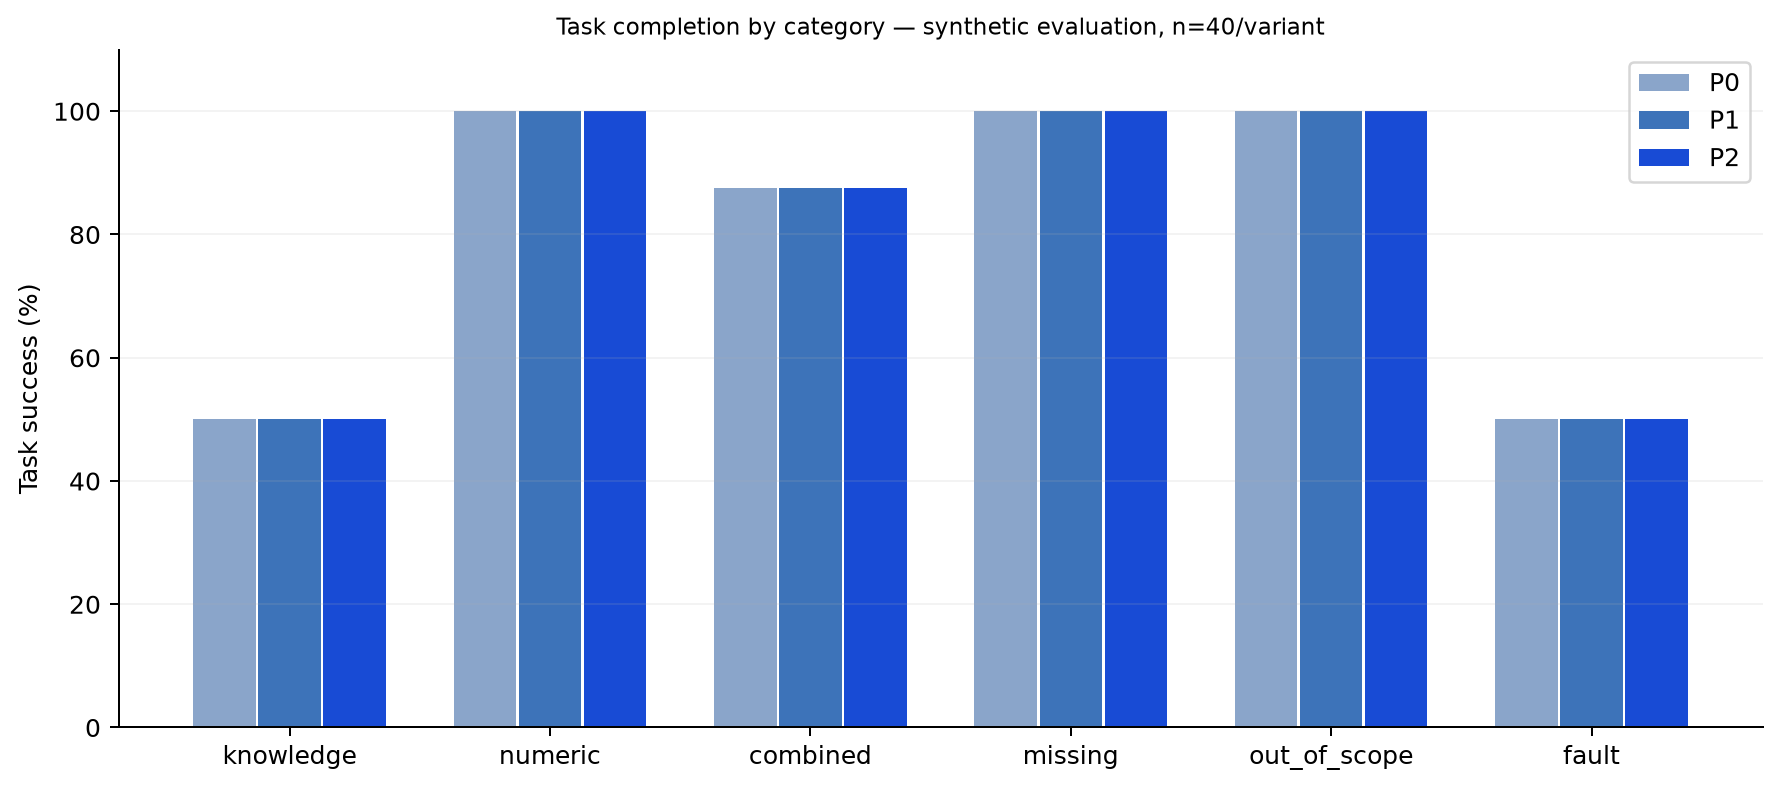

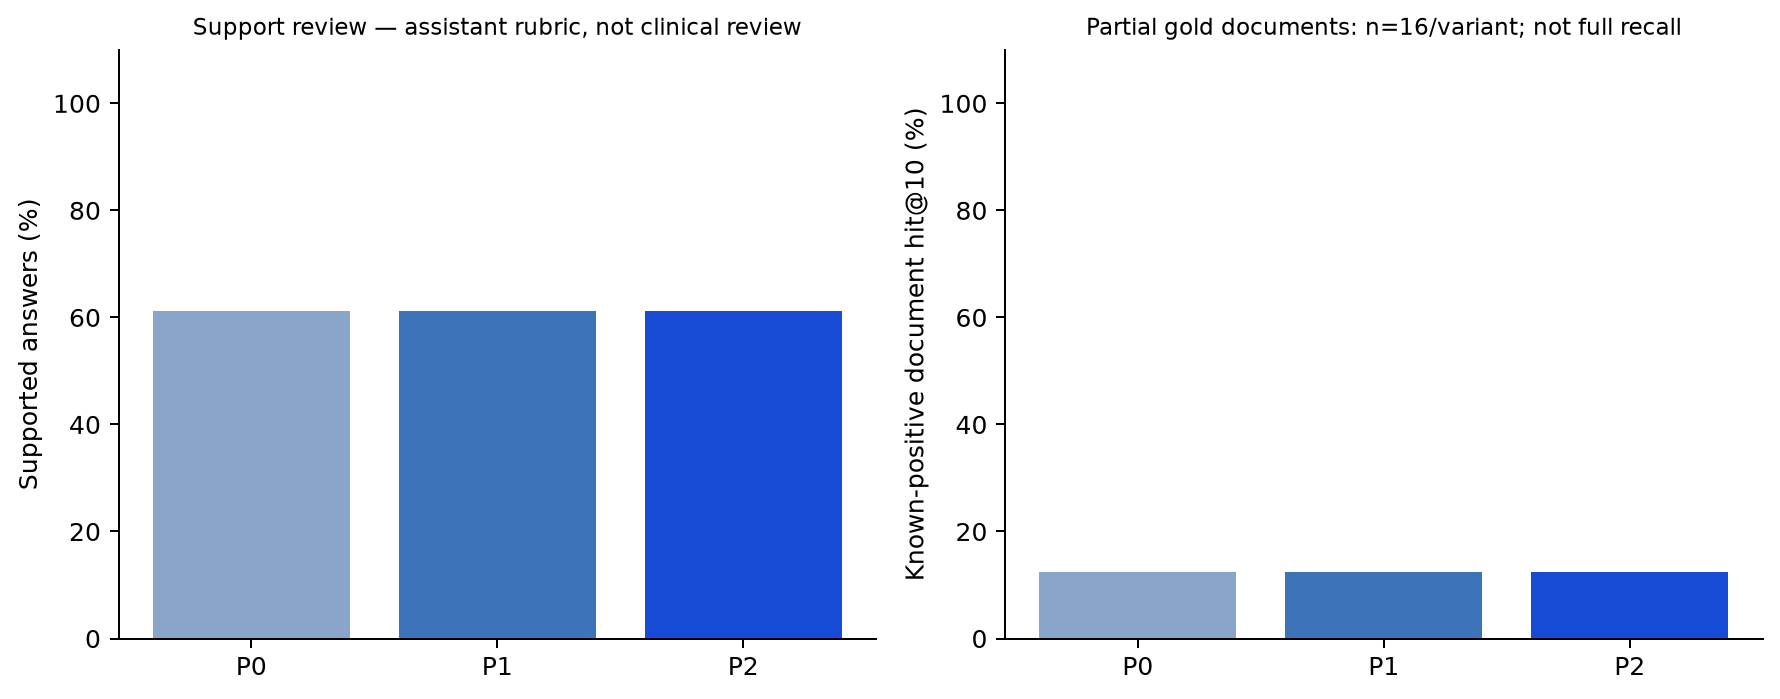

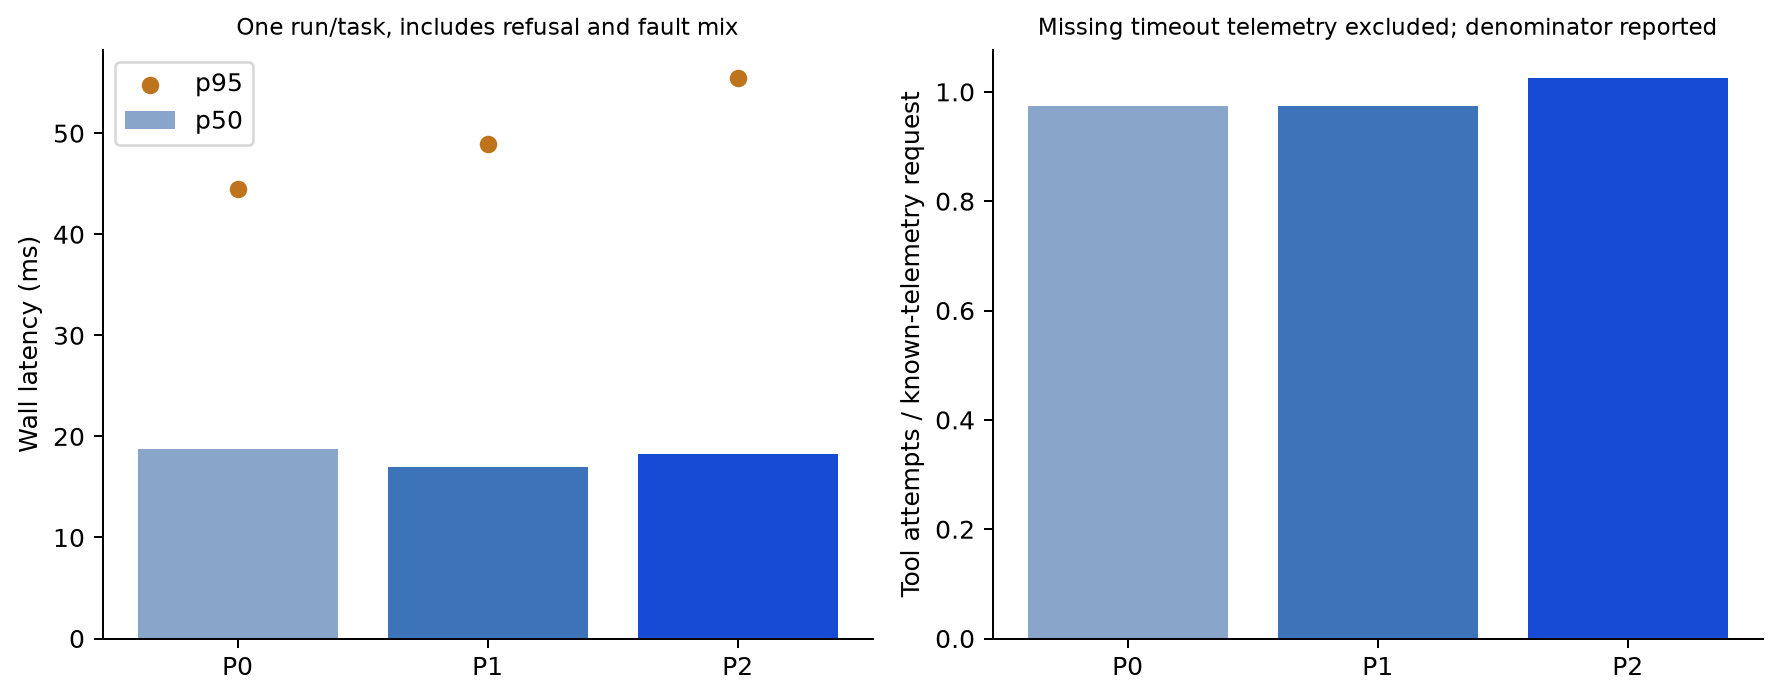

In [19]:
from project01_core.evaluation import read_results, summarize, plot_results
folder=PROJECT/'artifacts/phase2/evaluation'
if (folder/'results').exists():
    rows=read_results(folder/'results')
    display(summarize(rows))
    plot_results(rows,PROJECT/'report/figures')
    from IPython.display import Image, display
    for name in ['task_success.png','evidence_and_coverage.png','latency_tools.png']:
        display(Image(filename=str(PROJECT/'report/figures'/name)))
else:
    print('Chưa có evaluation; không tự chạy khi Run All.')
